In [12]:
!pip -q install torch numpy matplotlib

In [13]:
import re, json, unicodedata, urllib.request
from collections import Counter
import numpy as np, torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
torch.manual_seed(0)

In [14]:
url = 'https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt'
surowy = urllib.request.urlopen(url).read().decode('utf-8')

tekst = unicodedata.normalize('NFC', surowy)
tekst = re.sub(r'<[^>]+>', '', tekst)
tekst = tekst.replace('\r\n', '\n').replace('\xa0', ' ')
tekst = re.split(r'\n-----|Ta lektura,', tekst)[0]     # stopka serwisu
tekst = re.sub(r'\n{3,}', '\n\n', tekst).strip()

print('Surowy tekst:', len(surowy), '| po czyszczeniu:', len(tekst))
print('POCZĄTEK:', repr(tekst[:300]))
print('KONIEC  :', repr(tekst[-200:]))

Surowy tekst: 784082 | po czyszczeniu: 772632
POCZĄTEK: 'Bolesław Prus\n\nLalka\n\nISBN 978-83-288-2673-1\n\nTom I\n\nI. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?\n\nW początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja p'
KONIEC  : ' niestety! zaczynam przypuszczać, że baba miała rację…\n\nChociaż z tym odrodzonym Stachem Wokulskim człowiek nie jest pewny. A nuż?… O, to śmiałbym się z doktora Szumana, który tak żartuje z polityki!…'


In [15]:
n = len(tekst)
czesci = {
    'train': tekst[:int(0.8 * n)],
    'val':   tekst[int(0.8 * n):int(0.9 * n)],
    'test':  tekst[int(0.9 * n):],
}
for k, t in czesci.items():
    print(k, len(t), 'znaków')

train 618105 znaków
val 77263 znaków
test 77264 znaków


In [16]:
znaki = sorted(set(czesci['train']))
stoi = {z: i for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}
V = len(znaki)

def enc(s):  return [stoi.get(c, stoi[' ']) for c in s]
def dec(ids): return ''.join(itos[i] for i in ids)

print('Rozmiar słownika:', V)
for k in ('val', 'test'):
    obce = [c for c in czesci[k] if c not in stoi]
    print(f'{k}: znaki spoza słownika: {len(obce)}', sorted(set(obce)))

probka = czesci['train'][:500]
assert dec(enc(probka)) == probka
print('Test enc/dec: OK')

dane = {k: np.array(enc(t), dtype=np.int64) for k, t in czesci.items()}
tekst_dec = {k: dec(dane[k].tolist()) for k in dane}   # tekst po zakodowaniu (do porównań)

Rozmiar słownika: 101
val: znaki spoza słownika: 0 []
test: znaki spoza słownika: 0 []
Test enc/dec: OK


In [17]:
# Dataset i DataLoader
class DatasetZnakowy(Dataset):
    def __init__(self, dane, sekw):
        self.dane = dane; self.sekw = sekw
    def __len__(self):
        return len(self.dane) - self.sekw
    def __getitem__(self, i):
        x = self.dane[i:i+self.sekw]
        y = self.dane[i+1:i+self.sekw+1]   # przesunięcie o 1
        return torch.tensor(x), torch.tensor(y)

SEKW, BATCH = 40, 32
ds = {k: DatasetZnakowy(dane[k], SEKW) for k in dane}
dl = {k: DataLoader(ds[k], batch_size=BATCH, shuffle=(k == 'train'), drop_last=(k == 'train'))
      for k in ds}
print('SEKW =', SEKW, '| batch_size =', BATCH, '| krok okna = 1')

SEKW = 40 | batch_size = 32 | krok okna = 1


In [18]:
# Sanity-check: po jednym batchu z każdego zbioru
for k in dl:
    xb, yb = next(iter(dl[k]))
    print(f'[{k}] X: {tuple(xb.shape)}  Y: {tuple(yb.shape)}  ID: {xb.min().item()}..{xb.max().item()} (V={V})')
    assert xb.min() >= 0 and xb.max() < V and yb.max() < V

    w, c = dec(xb[0].tolist()), dec(yb[0].tolist())
    poz = tekst_dec[k].find(w)
    assert poz >= 0 and tekst_dec[k][poz+1:poz+1+SEKW] == c and w[1:] == c[:-1]
    print('  Wejście:', repr(w))
    print('  Cel    :', repr(c))

[train] X: (32, 40)  Y: (32, 40)  ID: 0..100 (V=101)
  Wejście: 'e skończę…\n\n— To i jazda do Mincla! — rz'
  Cel    : ' skończę…\n\n— To i jazda do Mincla! — rze'
[val] X: (32, 40)  Y: (32, 40)  ID: 0..100 (V=101)
  Wejście: 'e jutro kamienicę… kamienicę pana Łęckie'
  Cel    : ' jutro kamienicę… kamienicę pana Łęckieg'
[test] X: (32, 40)  Y: (32, 40)  ID: 1..95 (V=101)
  Wejście: 'ił się pannie Izabeli Starski jako mąż, '
  Cel    : 'ł się pannie Izabeli Starski jako mąż, R'


In [22]:
# Statystyki zbiorów (SEKW = 40)
for k in czesci:
    print(f'- {k} -')
    print(f'Znaków            : {len(czesci[k])}')
    print(f'Udział w korpusie : {100*len(czesci[k])/n:.1f}%')
    print(f'Różnych znaków    : {len(set(czesci[k]))}')
    print(f'Par (SEKW={SEKW})    : {len(ds[k])}')
    print(f'Batchy            : {len(dl[k])}')

- train -
Znaków            : 618105
Udział w korpusie : 80.0%
Różnych znaków    : 101
Par (SEKW=40)    : 618065
Batchy            : 19314
- val -
Znaków            : 77263
Udział w korpusie : 10.0%
Różnych znaków    : 74
Par (SEKW=40)    : 77223
Batchy            : 2414
- test -
Znaków            : 77264
Udział w korpusie : 10.0%
Różnych znaków    : 81
Par (SEKW=40)    : 77224
Batchy            : 2414


SEKW = 20  | par: train 618085, val 77243, test 77244
SEKW = 40  | par: train 618065, val 77223, test 77224
SEKW = 80  | par: train 618025, val 77183, test 77184
SEKW = 160 | par: train 617945, val 77103, test 77104


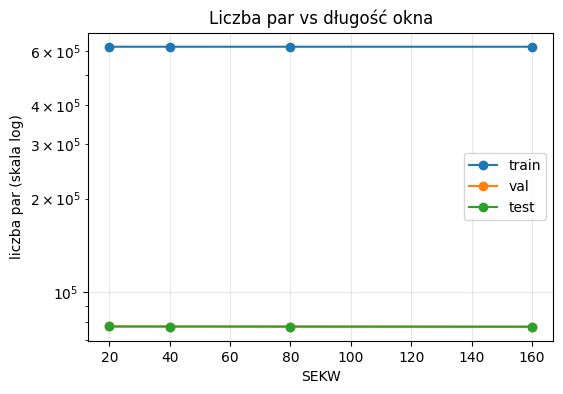

In [20]:
#Wpływ długości okna SEKW na liczbę par

SEKWY = [20, 40, 80, 160]
pary = {k: [len(DatasetZnakowy(dane[k], s)) for s in SEKWY] for k in dane}

for i, s in enumerate(SEKWY):
    print(f'SEKW = {s:<3} | par: train {pary["train"][i]}, val {pary["val"][i]}, test {pary["test"][i]}')

plt.figure(figsize=(6, 4))
for k in pary:
    plt.plot(SEKWY, pary[k], marker='o', label=k)
plt.yscale('log'); plt.xlabel('SEKW'); plt.ylabel('liczba par (skala log)')
plt.title('Liczba par vs długość okna'); plt.legend(); plt.grid(alpha=.3)
plt.savefig('wykres_sekw.png', dpi=150, bbox_inches='tight'); plt.show()

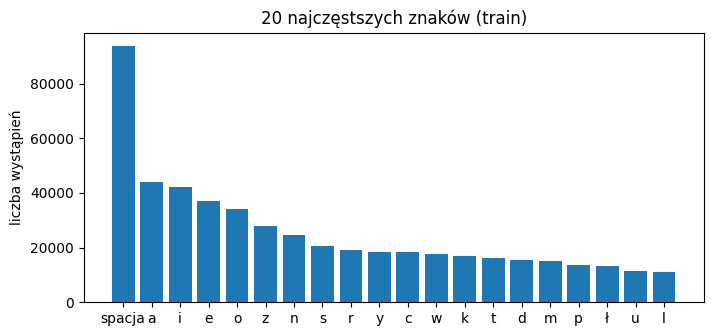

Słów w treningu: 93276 | różnych: 19584


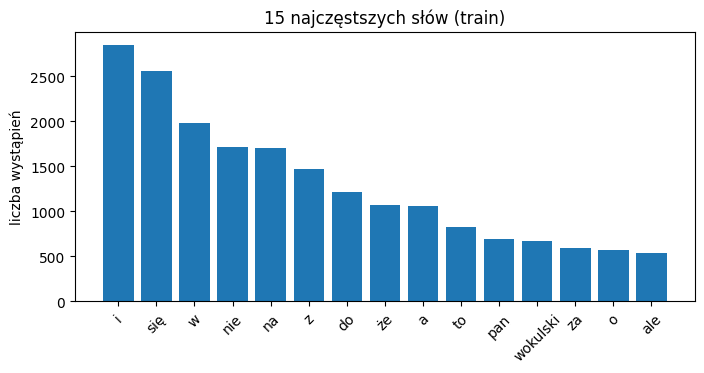

In [21]:
# Najczęstsze znaki i słowa (train)
nazwy = {' ': 'spacja', '\n': '\\n'}
top_z = Counter(czesci['train']).most_common(20)
plt.figure(figsize=(8, 3.5))
plt.bar([nazwy.get(z, z) for z, _ in top_z], [c for _, c in top_z])
plt.title('20 najczęstszych znaków (train)'); plt.ylabel('liczba wystąpień')
plt.savefig('wykres_znaki.png', dpi=150, bbox_inches='tight'); plt.show()

slowa = re.findall(r'\w+', czesci['train'].lower())
top_s = Counter(slowa).most_common(15)
print('Słów w treningu:', len(slowa), '| różnych:', len(set(slowa)))
plt.figure(figsize=(8, 3.5))
plt.bar([s for s, _ in top_s], [c for _, c in top_s])
plt.title('15 najczęstszych słów (train)'); plt.xticks(rotation=45); plt.ylabel('liczba wystąpień')
plt.savefig('wykres_slowa.png', dpi=150, bbox_inches='tight'); plt.show()